# **Data collection from OpenChargeMAP API**

In [18]:
# Import libraries
import requests
import pandas as pd
from scipy.spatial.distance import pdist

In [2]:
 #API URL
api_url = "https://api.openchargemap.io/v3/poi"

# **Collecting Dataset for the India location**

In [3]:
# API Parameters
params = {
    "countrycode": "EG",  # ISO country code for India
    "maxresults": 1000,   # Adjust as needed; note that very high numbers may lead to timeouts or incomplete data
    "compact": "true",    # Returns a simplified version of the data
    "verbose": "false",   # Limits the amount of data returned
    "key": "39ceaf3b-388a-4739-b48a-3da166575c87"
}


In [4]:
# Function to fetch data from Open Charge Map API
def fetch_station_data():
    response = requests.get(api_url, params=params)

    if response.status_code == 200:
        data = response.json()
        return data
        print("Success")
    else:
        print(f"Error: {response.status_code}")
        return []


In [26]:
def extract_relevant_features(data):
    """
    Extract relevant attributes from raw OpenChargeMap data.
    Adds RegionCategory based on Town.
    """
    # Mapping Town → RegionCategory
    town_to_region = {
        # Cairo Governorate
        "New Cairo": "Cairo",
        "Maadi": "Cairo",
        "Mokattam": "Cairo",
        "Nasr City": "Cairo",
        "Downtown": "Cairo",
        "Dokki": "Cairo",
        "Zamalek": "Cairo",
        "Garden City": "Cairo",
        "Masr El Gedida": "Cairo",
        "Madinet Nasr": "Cairo",
        "Abasseya": "Cairo",
        "New Heliopolis": "Cairo",
        "Shorouk": "Cairo",
        "Shrouk": "Cairo",
        "Madinaty": "Cairo",
        "Zohor": "Cairo",

        # Giza Governorate
        "October City": "Giza",
        "6th of October": "Giza",
        "Kattameya": "Giza",
        "Sheikh Zayed": "Giza",
        "Sadat": "Giza",
        "Sadat City": "Giza",
        "Nubariya": "Giza",

        # Alexandria Governorate
        "Alexandria": "Alexandria",
        "Borg El Arab": "Alexandria",
        "Miami": "Alexandria",
        "Alamein": "Alexandria",

        # Red Sea Governorate
        "Hurghada": "Red Sea",
        "Sahl Hasheesh": "Red Sea",
        "Makadi": "Red Sea",
        "Makadi Bay": "Red Sea",
        "Somabay": "Red Sea",
        "Sokhna": "Red Sea",
        "Ain Sokhna": "Red Sea",
        "Gouna": "Red Sea",
        "Il Monte Galala": "Red Sea",

        # South Sinai
        "Sharm El Sheikh": "South Sinai",
        "Dahab": "South Sinai",
        "Nuweiba": "South Sinai",
        "Ras Sedr": "South Sinai",

        # Matrouh Governorate
        "Ras El Hikma": "Matrouh",
        "Matrouh": "Matrouh",

        # New Administrative / Capital areas
        "New Capital": "New Administrative Capital",
        "Administrative Capital": "New Administrative Capital",
        "Sarai": "New Administrative Capital",

        # Other governorates
        "Port Said": "Port Said",
        "Suez": "Suez",
        "Assyut": "Assyut",
        "Fayoum": "Fayoum",
    }

    attributes = []
    for item in data:
        address_info = item.get("AddressInfo", {})
        connections = item.get("Connections", [])
        usage_type = item.get("UsageType", {})
        status_type = item.get("StatusType", {})

        # Determine State
        state = address_info.get("StateOrProvince") or address_info.get("Town", "Unknown")

        # Determine RegionCategory
        town_name = address_info.get("Town", "Unknown")
        region_category = town_to_region.get(town_name, "Other")

        attributes.append({
            "StationID": item.get("ID"),
            "StationName": address_info.get("Title"),
            "Latitude": address_info.get("Latitude"),
            "Longitude": address_info.get("Longitude"),
            "Address": address_info.get("AddressLine1"),
            "NumChargingPorts": len(connections),
            "ChargerType": [conn.get("ConnectionType", {}).get("Title") for conn in connections],
            "OperationalStatus": status_type.get("Title", "Unknown"),
            "UsageType": usage_type.get("Title", "Unknown"),
            "Country": address_info.get("Country", {}).get("Title", "Egypt"),
            "City": town_name,
            # "State": state,
            "RegionCategory": region_category,
            "Last_Updated": item.get("DateLastStatusUpdate")
        })
    return attributes

In [36]:
def haversine_distance(coord1, coord2, R=6371.0):
    """Compute Haversine distance between two (lat, lon) in radians"""
    dlat = coord2[0] - coord1[0]
    dlon = coord2[1] - coord1[1]
    a = np.sin(dlat/2)**2 + np.cos(coord1[0]) * np.cos(coord2[0]) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

# -------------------------------
# Calculate average distance per station
# -------------------------------
def add_avg_distance_per_station(df):
    avg_distances = []

    for _, group in df.groupby('RegionCategory'):
        coords = np.radians(group[['Latitude', 'Longitude']].to_numpy())
        n = len(coords)
        for i in range(n):
            if n == 1:
                avg_distances.append(0.0)
            else:
                dists = np.array([haversine_distance(coords[i], coords[j])
                                  for j in range(n) if j != i])
                avg_distances.append(dists.mean())
    df['AvgDistancePerStation_km'] = avg_distances
    return df

In [39]:
# # Fetch and process data
# data = fetch_station_data()
# if data:
#     attributes = extract_relevant_features(data)
#     df = pd.DataFrame(attributes)

#     # Add average distance column
#     df = add_avg_distance_column(df)

#     # Save to CSV
#     df.to_csv("avg.csv", index=False)

#     print(df.head())


data = fetch_station_data()
if data:
    df = pd.DataFrame(extract_relevant_features(data))
    df = add_avg_distance_per_station(df)
    df.to_csv("avg_distance_stations.csv", index=False)
    # print(df.head())

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 468 entries, 0 to 467
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StationID          468 non-null    int64  
 1   StationName        468 non-null    object 
 2   Latitude           468 non-null    float64
 3   Longitude          468 non-null    float64
 4   Address            462 non-null    object 
 5   NumChargingPorts   468 non-null    int64  
 6   ChargerType        468 non-null    object 
 7   OperationalStatus  468 non-null    object 
 8   UsageType          468 non-null    object 
 9   Country            468 non-null    object 
 10  City               468 non-null    object 
 11  RegionCategory     468 non-null    object 
 12  Last_Updated       468 non-null    object 
dtypes: float64(2), int64(2), object(9)
memory usage: 47.7+ KB


In [9]:
df.shape

(468, 13)

Code Explanation
Dataset Handling:

Loaded the dataset and checked its structure (data.info()).
Filled missing values in critical columns (Proximity, OperationalStatus, UsageType).



EDA:

Visualized the distribution of charging ports using sns.countplot.
Used sns.heatmap to identify correlations among numerical features.
Model Training:

Used RandomForestClassifier for classification.
Split data into training and testing sets, scaled the numerical features.
Evaluation:

Generated a classification report and confusion matrix.
Calculated MAE and RMSE for regression metrics (if regression is used).

In [10]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error


# **Dataset Handling:**

In [41]:
# Load the dataset
data = pd.read_csv("/content/avg_distance_stations.csv")


In [42]:
# Display basic information
print(data.info())
print(data.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 468 entries, 0 to 467
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   StationID                 468 non-null    int64  
 1   StationName               468 non-null    object 
 2   Latitude                  468 non-null    float64
 3   Longitude                 468 non-null    float64
 4   Address                   462 non-null    object 
 5   NumChargingPorts          468 non-null    int64  
 6   ChargerType               468 non-null    object 
 7   OperationalStatus         468 non-null    object 
 8   UsageType                 468 non-null    object 
 9   Country                   468 non-null    object 
 10  City                      468 non-null    object 
 11  RegionCategory            468 non-null    object 
 12  Last_Updated              468 non-null    object 
 13  AvgDistancePerStation_km  468 non-null    float64
dtypes: float64

In [43]:
# Total number of StationIDs (including duplicates)
print(f"Total StationID entries: {len(data['StationID'])}")

# Number of unique StationIDs
print(f"Number of unique StationIDs: {data['StationID'].nunique()}")


Total StationID entries: 468
Number of unique StationIDs: 468


In [44]:
# Handle missing values
data.fillna({'Proximity': 0, 'OperationalStatus': 'Unknown', 'UsageType': 'Unknown'}, inplace=True)


# **Feature Engineering:**

In [45]:
# Encode categorical variables
le = LabelEncoder()
data['OperationalStatus'] = le.fit_transform(data['OperationalStatus'])
data['UsageType'] = le.fit_transform(data['UsageType'])


In [46]:
# Create geospatial features
data['Lat_Long'] = data['Latitude'].astype(str) + "_" + data['Longitude'].astype(str)
data['State_StationID'] = data['City'] + "_" + data['StationID'].astype(str)


Encoded categorical features using LabelEncoder.

Created new geospatial and categorical features (e.g., Lat_Long, State_StationID).

# **Countplot**

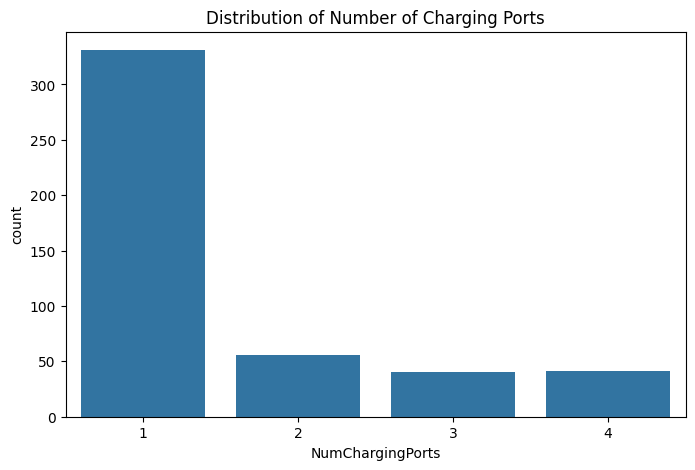

In [47]:
# Plot distribution of charging ports
plt.figure(figsize=(8, 5))
sns.countplot(x='NumChargingPorts', data=data)
plt.title("Distribution of Number of Charging Ports")
plt.show()

# **Heatmap**

**Correlation values range from:**
1. +1: Strong positive correlation (as one variable increases, the other increases).
2. -1: Strong negative correlation (as one variable increases, the other decreases).
3. 0: No correlation.

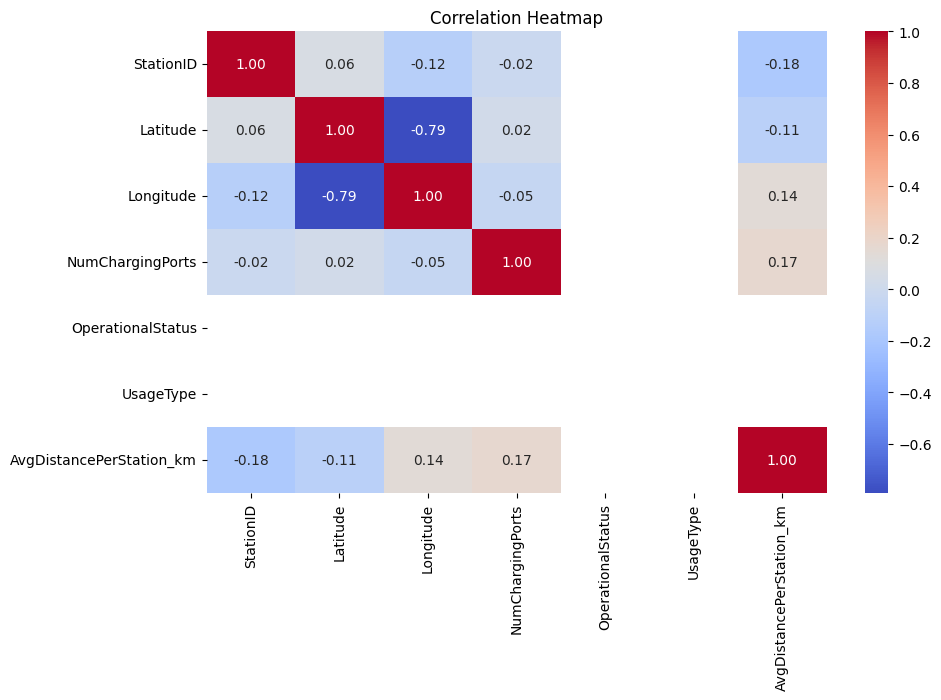

In [48]:
# Select only numeric columns
numeric_data = data.select_dtypes(include=['number'])

# Compute correlations
correlations = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlations, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()


**Independent Features:**

1. Many features show low correlations with each other, which suggests they are mostly independent. This is good for machine learning models since independence often prevents multicollinearity issues.
2. Geographical Impact:The strong negative correlation between Latitude and Postcode suggests a clear geographical trend. You might leverage this to segment stations or analyze usage based on regions.
3. Feature Engineering:
Features like Proximity and NumChargingPorts may need additional external data (e.g., population density, traffic patterns) to find stronger relationships and make them more useful in your project.

In [49]:
# Prepare data for model
X = data[['Latitude', 'Longitude', 'NumChargingPorts', 'OperationalStatus']]
y = data['OperationalStatus']  # Target variable

In [50]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [51]:
# Standardize the numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [52]:
# Train a Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [53]:
# Predict on test data
y_pred = rf_model.predict(X_test)


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        94

    accuracy                           1.00        94
   macro avg       1.00      1.00      1.00        94
weighted avg       1.00      1.00      1.00        94



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


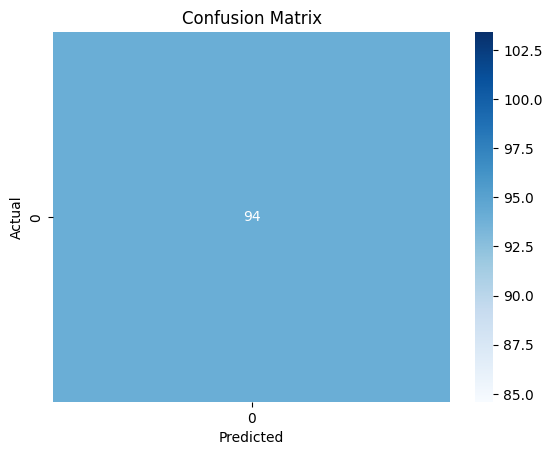

In [54]:
# Model Evaluation
print("Classification Report:\n", classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**1. Precision (1.00): The model correctly identified all positive predictions without any false positives.**

**2. Recall (1.00): The model correctly captured all the actual positive cases, without missing any.**

**3. F1-Score (1.00): The harmonic mean of precision and recall is also perfect.**

**4. Support (52): There were 52 samples in the test dataset, and the model correctly classified all of them.**

In [56]:
# Load the dataset
data = pd.read_csv("/content/avg_distance_stations.csv")

Geospatial Clustering
We'll apply KMeans clustering on Latitude and Longitude to group nearby charging stations and derive insights about station usage patterns.

In [57]:
from sklearn.cluster import KMeans
import folium

# Apply KMeans clustering
kmeans = KMeans(n_clusters=4, random_state=42)
data['Cluster'] = kmeans.fit_predict(data[['Latitude', 'Longitude']])

# Visualize clusters on a map using Folium
map_clusters = folium.Map(location=[data['Latitude'].mean(), data['Longitude'].mean()], zoom_start=10)

for _, row in data.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Station: {row['StationName']}, Cluster: {row['Cluster']}",
        icon=folium.Icon(color='blue' if row['Cluster'] == 0 else 'green')
    ).add_to(map_clusters)

# Save map to HTML
map_clusters.save("ev_station_clusters.html")


In [58]:
import folium
from folium.plugins import MarkerCluster

# Create a map centered around the mean coordinates
map_center = [data['Latitude'].mean(), data['Longitude'].mean()]
mymap = folium.Map(location=map_center, zoom_start=8)

# Create a marker cluster
marker_cluster = MarkerCluster().add_to(mymap)

# Add markers for each station, color-coded by cluster
colors = ['red', 'blue', 'green', 'purple', 'orange']  # Define colors for clusters
for i, row in data.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Station: {row['StationName']}<br>Cluster: {row['Cluster']}",
        icon=folium.Icon(color=colors[row['Cluster'] % len(colors)])  # Cycle through colors
    ).add_to(marker_cluster)

# Display the map directly in the notebook
mymap
